<a href="https://colab.research.google.com/github/nobe6i/machine_learning_class/blob/main/BAN674_Group1_Assignment1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [184]:
import pandas as pd
import numpy as np
import os

from google.colab import drive
from pandas.core.arrays import categorical
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.linear_model import LinearRegression

%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns


# 1a. Summarized the dataset and key observation


# (1) Load and summerized the dataset

In [185]:
#load dataset and create a new dataframe
toyota_df = pd.read_csv("ToyotaCorolla.csv")
toyota_df.columns = [s.strip().replace(' ', '_') for s in toyota_df.columns]

In [186]:
#determine the data shape
print(f"The Toyota data has {toyota_df.shape[0]} rows and {toyota_df.shape[1]} columns")

#determine the column names of the dataname
print(f"Column names are {list(toyota_df.columns)}")

The Toyota data has 1436 rows and 39 columns
Column names are ['Id', 'Model', 'Price', 'Age_08_04', 'Mfg_Month', 'Mfg_Year', 'KM', 'Fuel_Type', 'HP', 'Met_Color', 'Color', 'Automatic', 'CC', 'Doors', 'Cylinders', 'Gears', 'Quarterly_Tax', 'Weight', 'Mfr_Guarantee', 'BOVAG_Guarantee', 'Guarantee_Period', 'ABS', 'Airbag_1', 'Airbag_2', 'Airco', 'Automatic_airco', 'Boardcomputer', 'CD_Player', 'Central_Lock', 'Powered_Windows', 'Power_Steering', 'Radio', 'Mistlamps', 'Sport_Model', 'Backseat_Divider', 'Metallic_Rim', 'Radio_cassette', 'Parking_Assistant', 'Tow_Bar']


In [187]:
# show the top and end 5 rows of dataset
print("First five rows :\n", toyota_df.head())
print("Last five rows :\n", toyota_df.tail())

First five rows :
    Id                                          Model  Price  Age_08_04  \
0   1  TOYOTA Corolla 2.0 D4D HATCHB TERRA 2/3-Doors  13500         23   
1   2  TOYOTA Corolla 2.0 D4D HATCHB TERRA 2/3-Doors  13750         23   
2   3  TOYOTA Corolla 2.0 D4D HATCHB TERRA 2/3-Doors  13950         24   
3   4  TOYOTA Corolla 2.0 D4D HATCHB TERRA 2/3-Doors  14950         26   
4   5    TOYOTA Corolla 2.0 D4D HATCHB SOL 2/3-Doors  13750         30   

   Mfg_Month  Mfg_Year     KM Fuel_Type  HP  Met_Color  ... Powered_Windows  \
0         10      2002  46986    Diesel  90          1  ...               1   
1         10      2002  72937    Diesel  90          1  ...               0   
2          9      2002  41711    Diesel  90          1  ...               0   
3          7      2002  48000    Diesel  90          0  ...               0   
4          3      2002  38500    Diesel  90          0  ...               1   

   Power_Steering  Radio  Mistlamps  Sport_Model  Backseat_Di

In [188]:
# show the data type
toyota_df.dtypes


,0
Id,int64
Model,object
Price,int64
Age_08_04,int64
Mfg_Month,int64
Mfg_Year,int64
KM,int64
Fuel_Type,object
HP,int64
Met_Color,int64


In [189]:
#checking the missing values
print(f"The Toyota data has {toyota_df.isnull().sum().sum()} missing values")
toyota_df.isnull().sum()


The Toyota data has 0 missing values


,0
Id,0
Model,0
Price,0
Age_08_04,0
Mfg_Month,0
Mfg_Year,0
KM,0
Fuel_Type,0
HP,0
Met_Color,0


In [190]:
#check to see if any of the columns are binary catgories
binary_columns = [col for col in toyota_df.columns if toyota_df[col].isin([0, 1]).all()]
print("Columns containing only 0 and 1:", binary_columns)

Columns containing only 0 and 1: ['Met_Color', 'Automatic', 'Mfr_Guarantee', 'BOVAG_Guarantee', 'ABS', 'Airbag_1', 'Airbag_2', 'Airco', 'Automatic_airco', 'Boardcomputer', 'CD_Player', 'Central_Lock', 'Powered_Windows', 'Power_Steering', 'Radio', 'Mistlamps', 'Sport_Model', 'Backseat_Divider', 'Metallic_Rim', 'Radio_cassette', 'Parking_Assistant', 'Tow_Bar']


**Numerical Columns**

In [191]:
#summary statistics for numerical columns (excluding categorical columns and non-numerical columns)
num_df = toyota_df.drop(columns=binary_columns + ["Doors", "Cylinders", "Gears"], errors='ignore').select_dtypes(include=[np.number])

if not num_df.empty:
  num_summary = np.round(num_df.describe(), decimals=2)
  display(num_summary)
else:
  print("No numerical columns")

,Id,Price,Age_08_04,Mfg_Month,Mfg_Year,KM,HP,CC,Quarterly_Tax,Weight,Guarantee_Period
count,1436.00,1436.00,1436.00,1436.00,1436.00,1436.00,1436.00,1436.00,1436.00,1436.00,1436.00
mean,721.56,10730.82,55.95,5.55,1999.63,68533.26,101.50,1576.86,87.12,1072.46,3.82
std,416.48,3626.96,18.60,3.35,1.54,37506.45,14.98,424.39,41.13,52.64,3.01
min,1.00,4350.00,1.00,1.00,1998.00,1.00,69.00,1300.00,19.00,1000.00,3.00
25%,361.75,8450.00,44.00,3.00,1998.00,43000.00,90.00,1400.00,69.00,1040.00,3.00
50%,721.50,9900.00,61.00,5.00,1999.00,63389.50,110.00,1600.00,85.00,1070.00,3.00
75%,1081.25,11950.00,70.00,8.00,2001.00,87020.75,110.00,1600.00,85.00,1085.00,3.00
max,1442.00,32500.00,80.00,12.00,2004.00,243000.00,192.00,16000.00,283.00,1615.00,36.00


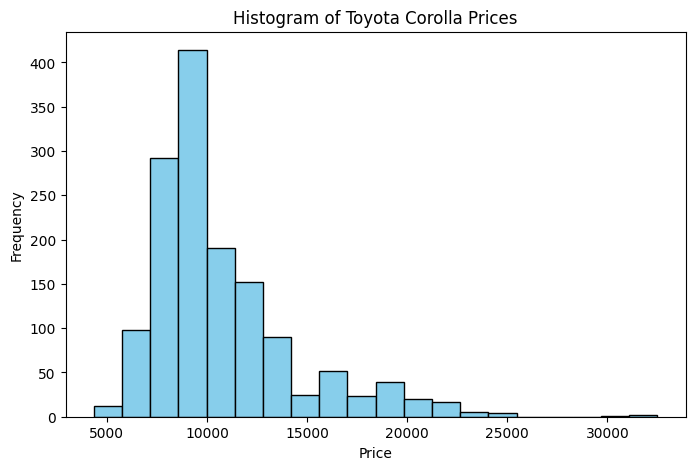

In [192]:
# Create a histogram for the 'Price' column
plt.figure(figsize=(8, 5))
plt.hist(toyota_df["Price"], bins=20, edgecolor='black', color='skyblue')
plt.title("Histogram of Toyota Corolla Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.savefig("toyota_price_histogram.png")
plt.show()

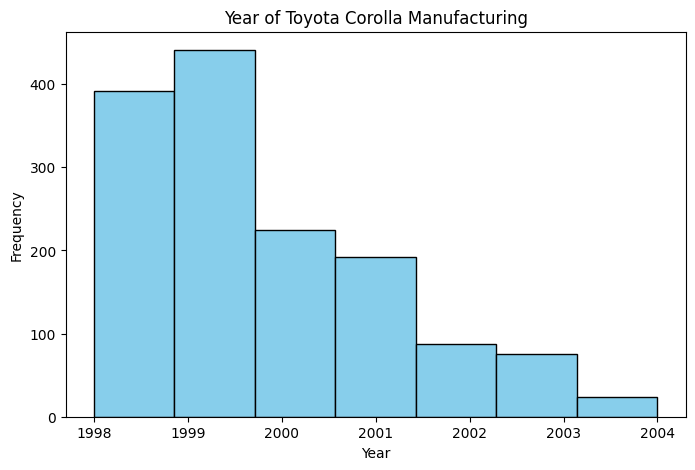

In [193]:
plt.figure(figsize=(8, 5))
plt.hist(toyota_df["Mfg_Year"], bins=7, edgecolor='black', color='skyblue')
plt.title("Year of Toyota Corolla Manufacturing")
plt.xlabel("Year")
plt.ylabel("Frequency")
plt.savefig("toyota_year_histogram.png")
plt.show()

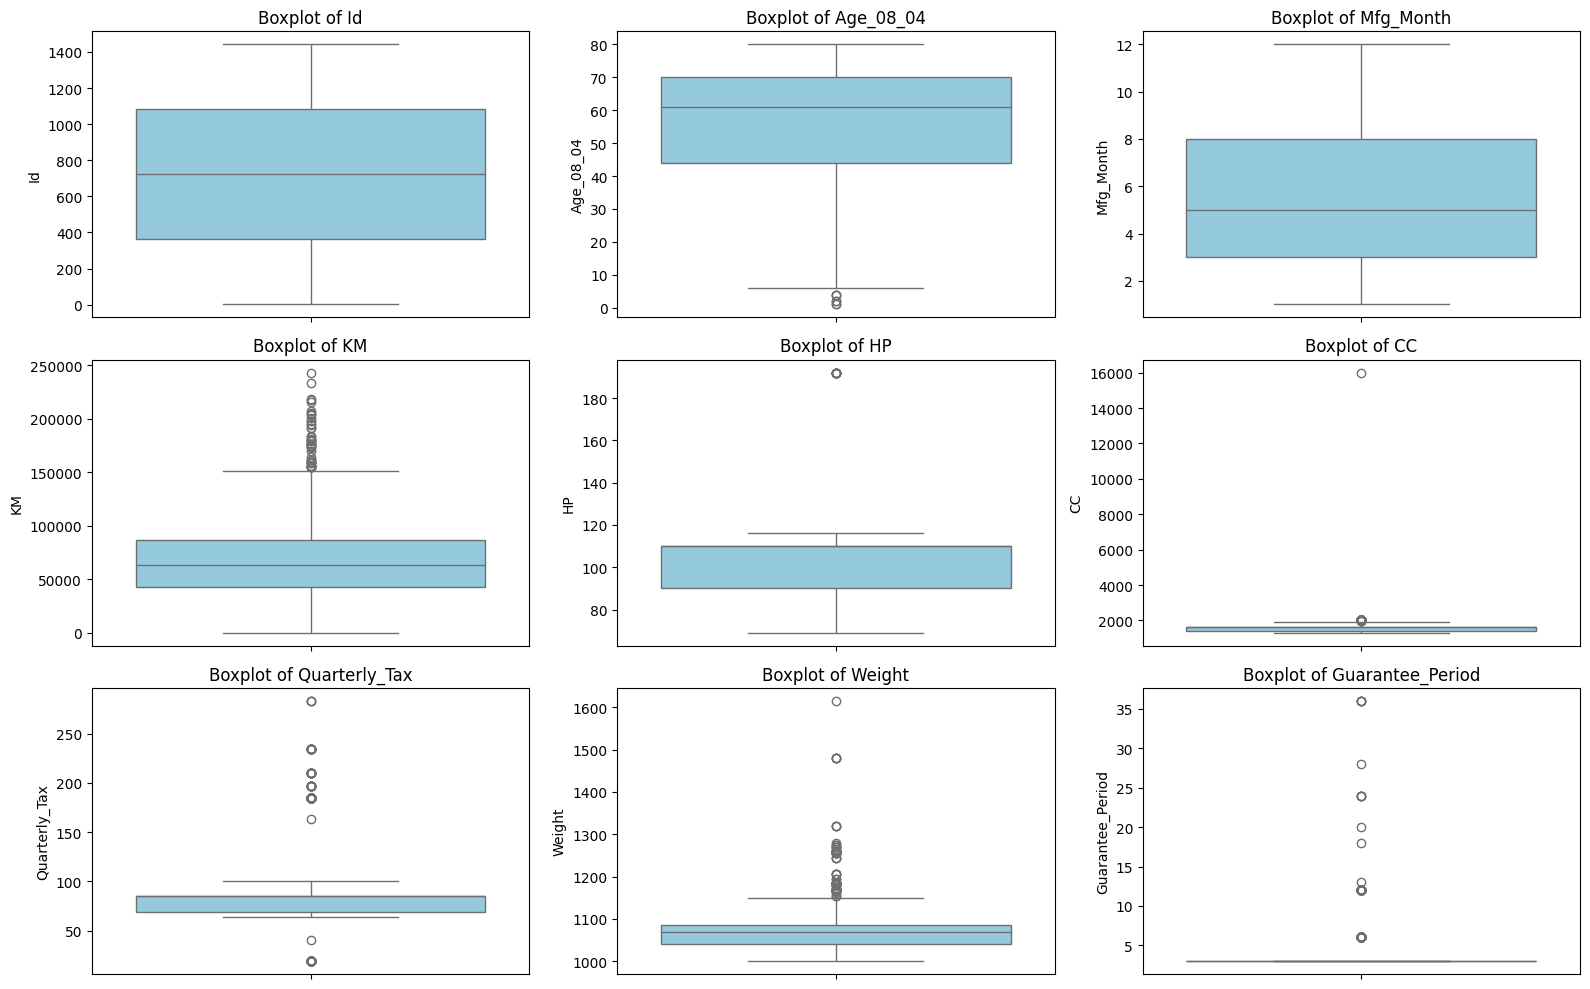

In [194]:
# Identify numerical columns to plot (excluding Price and Mfg_Year)
columns_to_plot = [col for col in num_df.columns if col not in ['Price', 'Mfg_Year']]

# Create boxplots for the remaining columns
plt.figure(figsize=(16, 10))
for i, col in enumerate(columns_to_plot, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=toyota_df[col], color='skyblue')
    plt.title(f'Boxplot of {col}')
    plt.ylabel(col)

plt.tight_layout()
plt.savefig("toyota_boxplots.png")
plt.show()

In [195]:
print(f'The num_df has {num_df.shape[1]} columns.')

The num_df has 11 columns.


**Categorical Columns**

In [196]:
# Check if 'Doors' and 'Gears' are integers; if not, cast them to integers
for col in ['Doors', 'Gears']:
    if not pd.api.types.is_integer_dtype(toyota_df[col]):
        toyota_df[col] = toyota_df[col].astype(int)

# Verify their data types
print(toyota_df[['Doors', 'Gears']].dtypes)

Doors    int64
Gears    int64
dtype: object


In [197]:
# Get the Categorical Columns

# Select object columns
object_cols = list(toyota_df.select_dtypes(include=['object']).columns)

# Combine with binary_columns, Doors, Cylinders, and Gears
categorical_cols = list(set(object_cols + binary_columns + ["Doors", "Cylinders", "Gears"]))

# Create the new categorical_df
categorical_df = toyota_df[categorical_cols].copy()

# Display the first few rows
display(categorical_df.head())

,Fuel_Type,Sport_Model,Mfr_Guarantee,CD_Player,Parking_Assistant,ABS,Radio_cassette,Central_Lock,Color,Radio,...,Power_Steering,Doors,Gears,Airco,Mistlamps,Metallic_Rim,Airbag_1,Backseat_Divider,Cylinders,BOVAG_Guarantee
0,Diesel,0,0,0,0,1,0,1,Blue,0,...,1,3,5,0,0,0,1,1,4,1
1,Diesel,0,0,1,0,1,0,1,Silver,0,...,1,3,5,1,0,0,1,1,4,1
2,Diesel,0,1,0,0,1,0,0,Blue,0,...,1,3,5,0,0,0,1,1,4,1
3,Diesel,0,1,0,0,1,0,0,Black,0,...,1,3,5,0,0,0,1,1,4,1
4,Diesel,0,1,0,0,1,0,1,Black,0,...,1,3,5,1,1,0,1,1,4,1


How many unique Models of Corollas does Toyota have?

In [198]:
toyota_df["Model"].nunique()

319

In [199]:
print(f'The categorical_df has {categorical_df.shape[1]} columns.')


The categorical_df has 28 columns.


In [200]:

# Summary statistics and frequency counts for categorical columns
display(categorical_df.describe())





,Sport_Model,Mfr_Guarantee,CD_Player,Parking_Assistant,ABS,Radio_cassette,Central_Lock,Radio,Automatic,Met_Color,...,Power_Steering,Doors,Gears,Airco,Mistlamps,Metallic_Rim,Airbag_1,Backseat_Divider,Cylinders,BOVAG_Guarantee
count,1436.000000,1436.000000,1436.000000,1436.000000,1436.00000,1436.000000,1436.000000,1436.000000,1436.000000,1436.000000,...,1436.000000,1436.000000,1436.000000,1436.000000,1436.000000,1436.000000,1436.000000,1436.000000,1436.0,1436.000000
mean,0.300139,0.409471,0.218663,0.002786,0.81337,0.145543,0.580084,0.146240,0.055710,0.674791,...,0.977716,4.033426,5.026462,0.508357,0.256964,0.204735,0.970752,0.770195,4.0,0.895543
std,0.458478,0.491907,0.413483,0.052723,0.38975,0.352770,0.493717,0.353469,0.229441,0.468616,...,0.147657,0.952677,0.188510,0.500104,0.437111,0.403649,0.168559,0.420854,0.0,0.305959
min,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,2.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.0,0.000000
25%,0.000000,0.000000,0.000000,0.000000,1.00000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,3.000000,5.000000,0.000000,0.000000,0.000000,1.000000,1.000000,4.0,1.000000
50%,0.000000,0.000000,0.000000,0.000000,1.00000,0.000000,1.000000,0.000000,0.000000,1.000000,...,1.000000,4.000000,5.000000,1.000000,0.000000,0.000000,1.000000,1.000000,4.0,1.000000
75%,1.000000,1.000000,0.000000,0.000000,1.00000,0.000000,1.000000,0.000000,0.000000,1.000000,...,1.000000,5.000000,5.000000,1.000000,1.000000,0.000000,1.000000,1.000000,4.0,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,5.000000,6.000000,1.000000,1.000000,1.000000,1.000000,1.000000,4.0,1.000000


In [201]:
def cat_dist(data, *column_names):
  for col in column_names:
    counts = data[col].value_counts()
    percentages = data[col].value_counts(normalize=True).mul(100).round(1).astype(str) + '%'
    dist_df = pd.DataFrame({'counts': counts, 'percentages': percentages})
    display(dist_df)

cat_dist(categorical_df, *categorical_df.columns)

,counts,percentages
Fuel_Type,,
Petrol,1264,88.0%
Diesel,155,10.8%
CNG,17,1.2%


,counts,percentages
Sport_Model,,
0,1005,70.0%
1,431,30.0%


,counts,percentages
Mfr_Guarantee,,
0,848,59.1%
1,588,40.9%


,counts,percentages
CD_Player,,
0,1122,78.1%
1,314,21.9%


,counts,percentages
Parking_Assistant,,
0,1432,99.7%
1,4,0.3%


...

,counts,percentages
Metallic_Rim,,
0,1142,79.5%
1,294,20.5%


,counts,percentages
Airbag_1,,
1,1394,97.1%
0,42,2.9%


,counts,percentages
Backseat_Divider,,
1,1106,77.0%
0,330,23.0%


,counts,percentages
Cylinders,,
4,1436,100.0%


,counts,percentages
BOVAG_Guarantee,,
1,1286,89.6%
0,150,10.4%


I am surprised so little cars have automatic transmissions and radios. I would think that they might have these Booleans mislabelled.

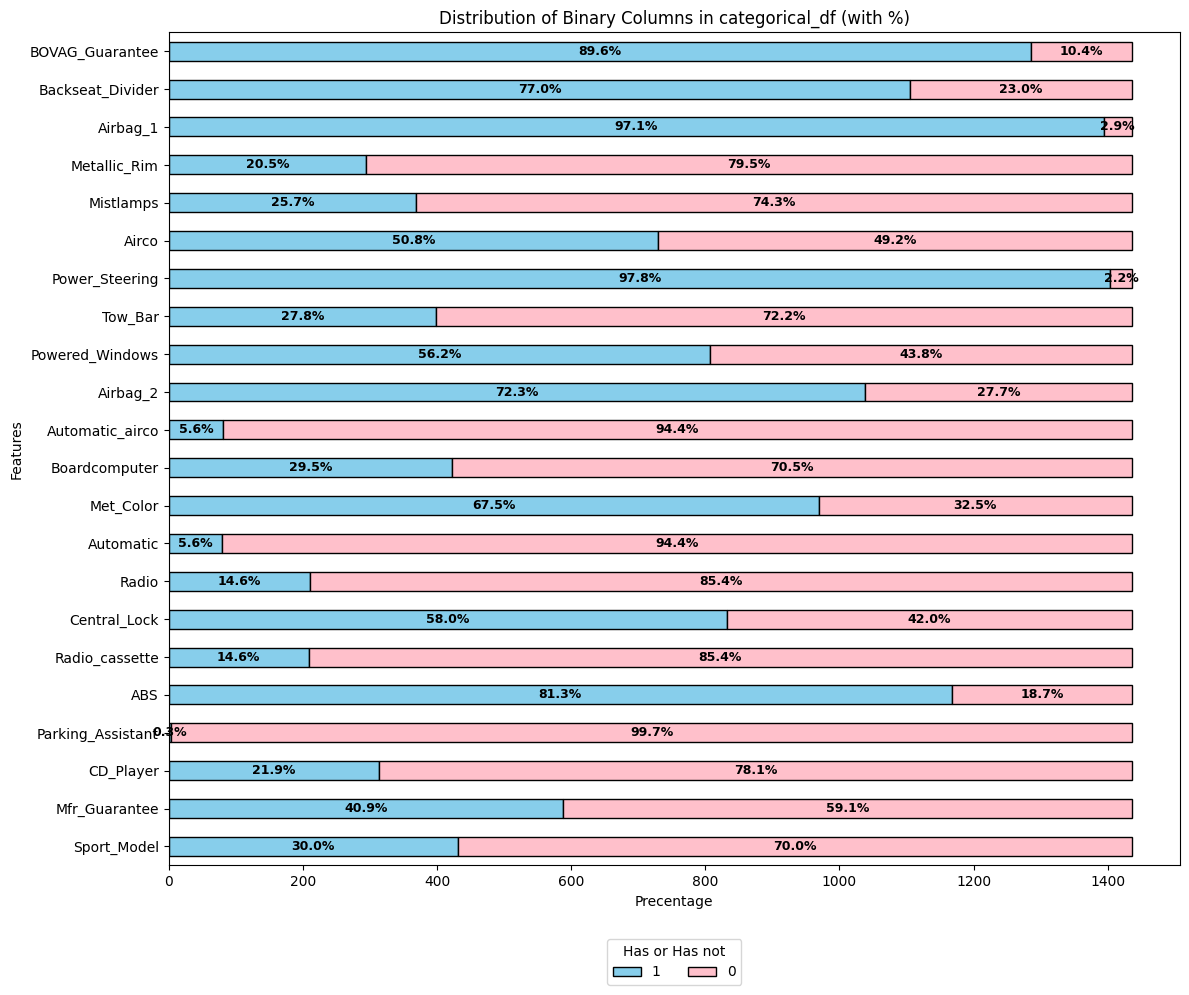

In [202]:
# Filter categorical_df to only include columns that are also in binary_columns
binary_df_cols = [col for col in categorical_df.columns if col in binary_columns]

# Calculate counts of 0 and 1 for each of these columns
binary_counts = pd.DataFrame({
    '1': [categorical_df[col].value_counts().get(1, 0) for col in binary_df_cols],
    '0': [categorical_df[col].value_counts().get(0, 0) for col in binary_df_cols]
}, index=binary_df_cols)

# Calculate row-wise percentages
binary_pcts = binary_counts.div(binary_counts.sum(axis=1), axis=0) * 100

# Plot a stacked horizontal bar chart
plt.figure(figsize=(12, 10))
ax = plt.gca()
binary_counts.plot(kind='barh', stacked=True, color=['skyblue', 'pink'], edgecolor='black', ax=ax)

# Annotate the percentages onto each bar segment
for i, container in enumerate(ax.containers):
    # Get category name ('1' or '0')
    col_name = '1' if i == 0 else '0'

    for j, patch in enumerate(container.get_children()):
        width = patch.get_width()
        if width > 0:  # Only annotate bars with non-zero width
            # Retrieve the corresponding percentage
            pct_val = binary_pcts.iloc[j][col_name]
            x_pos = patch.get_x() + width / 2
            y_pos = patch.get_y() + patch.get_height() / 2
            ax.text(x_pos, y_pos, f'{pct_val:.1f}%',
                    ha='center', va='center', fontsize=9, fontweight='bold', color='black')

plt.title('Distribution of Binary Columns in categorical_df (with %)')
plt.xlabel('Precentage')
plt.ylabel('Features')
plt.legend(title='Has or Has not', loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=2)

plt.tight_layout()
plt.savefig("toyota_binary_dist.png")
plt.show()

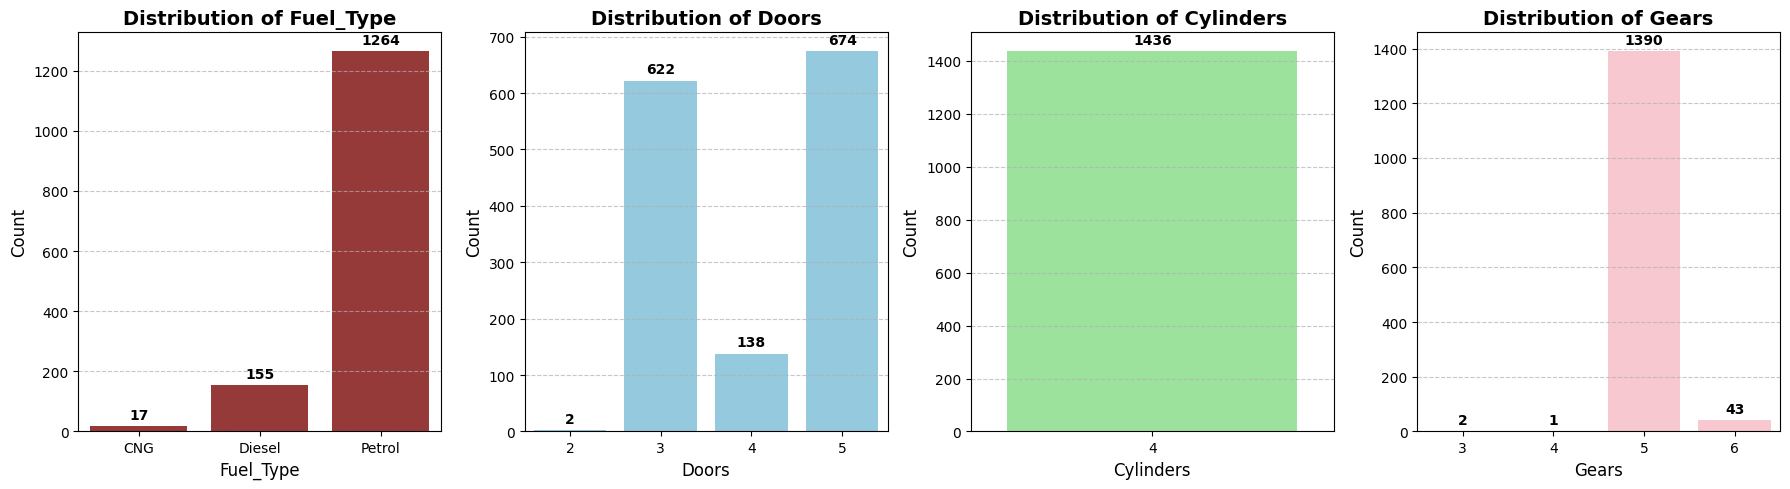

In [203]:
# Set up a single row with 3 subplots
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

# List of columns to plot
columns_to_plot = ['Fuel_Type','Doors', 'Cylinders', 'Gears']
colors = ['brown','skyblue', 'lightgreen', 'pink']

for i, col in enumerate(columns_to_plot):
    # Calculate value counts
    counts = toyota_df[col].value_counts().sort_index()

    # Plot counts as a bar graph on the corresponding subplot axis
    sns.barplot(x=counts.index, y=counts.values, ax=axes[i], palette=[colors[i]], hue=[col]*len(counts), legend=False)

    # Add counts on top of each bar
    for patch in axes[i].patches:
        height = patch.get_height()
        if height > 0:
            axes[i].annotate(f'{int(height)}',
                             xy=(patch.get_x() + patch.get_width() / 2, height),
                             xytext=(0, 3),  # 3 points vertical offset
                             textcoords="offset points",
                             ha='center', va='bottom', fontsize=10, fontweight='bold')

    axes[i].set_title(f'Distribution of {col}', fontsize=14, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=12)
    axes[i].set_ylabel('Count', fontsize=12)
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig("toyota_categorical_dist.png")
plt.show()

I hadn't realized that all Corrolas have 4 cylinders

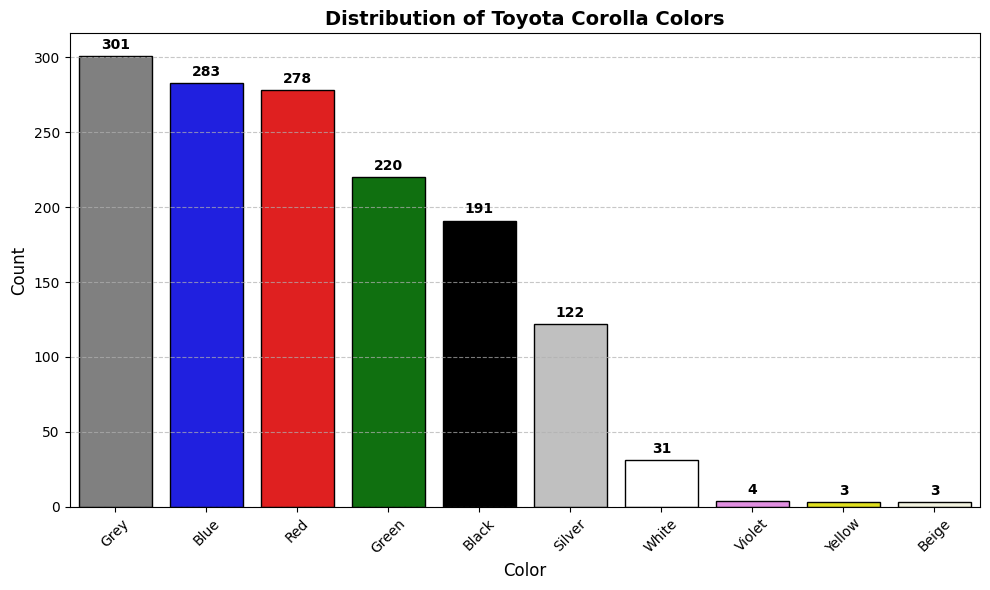

In [204]:
# Calculate the distribution of the 'Color' column
color_counts = toyota_df['Color'].value_counts()
pallete = ["grey","blue","red","green","black","silver","white","violet","yellow","beige"]

# Create a bar chart for the Color distribution
plt.figure(figsize=(10, 6))
ax = sns.barplot(x=color_counts.index, y=color_counts.values, palette=pallete, hue=color_counts.index, legend=False, edgecolor='black')

# Annotate counts on top of each bar
for patch in ax.patches:
    height = patch.get_height()
    if height > 0:
        ax.annotate(f'{int(height)}',
                    xy=(patch.get_x() + patch.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.title('Distribution of Toyota Corolla Colors', fontsize=14, fontweight='bold')
plt.xlabel('Color', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig("toyota_color_dist.png")
plt.show()

# 1b. Normaize the variable KM


In [205]:
# normalize KM

toyota_df['normalized_KM'] = (toyota_df['KM'] - toyota_df['KM'].mean()) / toyota_df['KM'].std()

toyota_df['normalized_KM']


,normalized_KM
0,-0.574495
1,0.117413
2,-0.715137
3,-0.547459
4,-0.800749
...,...
1431,-1.279494
1432,-1.320660
1433,-1.373557
1434,-1.376224


# 1c.  Create dummies for the variable Fule Type

In [206]:
# Use toyota_df['Fuel_Type'] to correctly reference the column
#first change the dtype of Fuel_Type from object into int
fuel_dummies = pd.get_dummies(

    toyota_df["Fuel_Type"],

    prefix="Fuel",

    dtype=int
)
toyota_df = pd.concat([toyota_df, fuel_dummies], axis=1)

print(toyota_df[[

    "Fuel_Type",

    "Fuel_CNG",

    "Fuel_Diesel",

    "Fuel_Petrol"

]].head(10))


  Fuel_Type  Fuel_CNG  Fuel_Diesel  Fuel_Petrol
0    Diesel         0            1            0
1    Diesel         0            1            0
2    Diesel         0            1            0
3    Diesel         0            1            0
4    Diesel         0            1            0
5    Diesel         0            1            0
6    Diesel         0            1            0
7    Diesel         0            1            0
8    Petrol         0            0            1
9    Diesel         0            1            0


# 1d.  Partition the data into three sets

In [207]:
# randomly sample 50% of the row IDs for training
trainData = toyota_df.sample(frac=0.5, random_state=1)
# sample 30% of the row IDs into the validation set, drawing only from records not already in the training set; 60% of 50% is 30%
validData = toyota_df.drop(trainData.index).sample(frac=0.6, random_state=1)
# the remaining 20% rows serve as test data
testData = toyota_df.drop(trainData.index).drop(validData.index)

print('Training   : ', trainData.shape)
print('Validation : ', validData.shape)
print('Test       : ', testData.shape)
print()

Training   :  (718, 43)
Validation :  (431, 43)
Test       :  (287, 43)



# 2.   Wine Case Dataset


In [208]:
# Load the  dataset as a pandas DataFrame
wine_df = pd.read_csv('Wine.csv')

# View the first few rows
print(wine_df.head())

  Type  Alcohol  Malic_Acid   Ash  Ash_Alcalinity  Magnesium  Total_Phenols  \
0    A    14.23        1.71  2.43            15.6        127           2.80   
1    A    13.20        1.78  2.14            11.2        100           2.65   
2    A    13.16        2.36  2.67            18.6        101           2.80   
3    A    14.37        1.95  2.50            16.8        113           3.85   
4    A    13.24        2.59  2.87            21.0        118           2.80   

   Flavanoids  Nonflavanoid_Phenols  Proanthocyanins  Color_Intensity   Hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   OD280_OD315  Proline  
0         3.92     1065 

In [209]:
wine_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Type                  178 non-null    object 
 1   Alcohol               178 non-null    float64
 2   Malic_Acid            178 non-null    float64
 3   Ash                   178 non-null    float64
 4   Ash_Alcalinity        178 non-null    float64
 5   Magnesium             178 non-null    int64  
 6   Total_Phenols         178 non-null    float64
 7   Flavanoids            178 non-null    float64
 8   Nonflavanoid_Phenols  178 non-null    float64
 9   Proanthocyanins       178 non-null    float64
 10  Color_Intensity       178 non-null    float64
 11  Hue                   178 non-null    float64
 12  OD280_OD315           178 non-null    float64
 13  Proline               178 non-null    int64  
dtypes: float64(11), int64(2), object(1)
memory usage: 19.6+ KB


In [210]:
wine_df.columns

Index(['Type', 'Alcohol', 'Malic_Acid', 'Ash', 'Ash_Alcalinity', 'Magnesium',
       'Total_Phenols', 'Flavanoids', 'Nonflavanoid_Phenols',
       'Proanthocyanins', 'Color_Intensity', 'Hue', 'OD280_OD315', 'Proline'],
      dtype='object')

In [211]:
wine_df.describe()

,Alcohol,Malic_Acid,Ash,Ash_Alcalinity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280_OD315,Proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


In [212]:
#normalize magnesium and proline levels
wine_df["normalized_magnesium"] = (wine_df['Magnesium'] - wine_df['Magnesium'].mean()) / wine_df['Magnesium'].std()
wine_df["normalized_proline"] = (wine_df['Proline'] - wine_df['Proline'].mean()) / wine_df['Proline'].std()

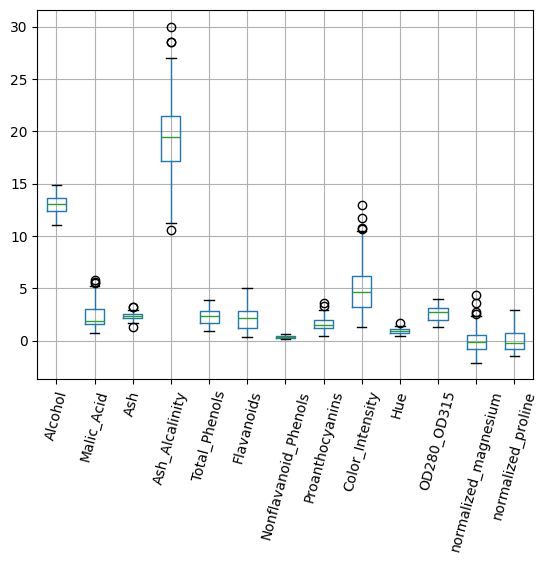

In [213]:
wine_df_norm=wine_df.copy()
wine_df_norm.drop(wine_df[["Magnesium","Proline"]], inplace=True, axis=1)
wine_df_norm

wine_df_norm.boxplot(rot=75)
plt.savefig("wine_boxplots.png")
plt.show()

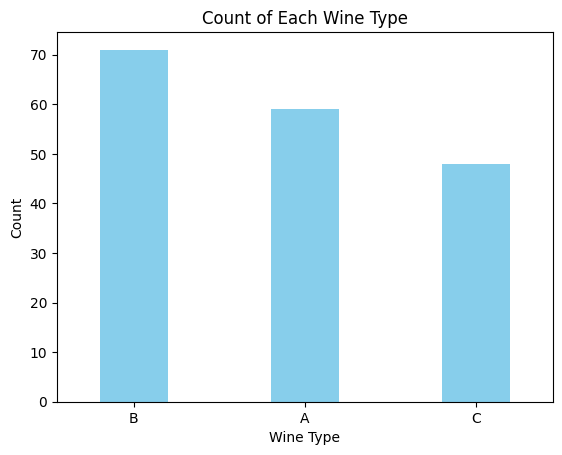

In [214]:
# Count the occurrences of each type and plot as a bar chart
wine_df["Type"].value_counts().plot(kind="bar", color="skyblue", width=0.4)

# Customize the chart
plt.title("Count of Each Wine Type")
plt.xlabel("Wine Type")
plt.ylabel("Count")
plt.xticks(rotation=0)  # Keeps the x-axis labels horizontal
plt.savefig("wine_type_dist.png")

# Display the plot
plt.show()